# Association Rule Mining via Apriori Algorithm in Python
This practical content is modified from https://medium.com/analytics-vidhya/association-analysis-in-python-2b955d0180c by Dr Hong Qing Yu (Harry)

**Association rule mining** is a technique to identify underlying relations between different items. In this practical we apply the **Apriori algorithm** from the lecture to do association rule mining.

Apriori is an algorithm for frequent itemset mining and association rule learning over relational databases. It starts by identifying the frequent individual items in the database and extends them to larger and larger itemsets as long as those itemsets appear sufficiently often in the database. The frequent itemsets found by Apriori can then be used to derive association rules, which highlight general trends in the database. A typical application is market basket analysis.

**How to run it:** this notebook runs in your browser, so there is nothing to install. Click a code cell and press **Shift + Enter** to run it, or use **Run → Run All Cells**. Run the cells in order. The first code cell installs `mlxtend` and `seaborn` into the browser, which takes a few seconds the first time. The data file `retail_dataset.csv` must stay in the same folder as this notebook.

**What to expect:** the dataset has 315 shopping baskets with 9 different items (Bagel, Bread, Cheese, Diaper, Eggs, Meat, Milk, Pencil, Wine). With a minimum support of 0.2, Apriori finds the frequent itemsets; for example, Bread and Cheese are each in about half of the baskets. With a minimum confidence of 0.6 it finds rules such as Bagel → Bread (confidence 0.66, lift 1.30) and Meat → Cheese (confidence 0.68, lift 1.36). The last three plots compare the support, confidence and lift of these rules. The order of the rows in the rule table can change from one run to the next.

Python has many libraries for apriori implementation. One can also implement the algorithm from scratch. But wait, there is mlxtend to the rescue. This library has a neat implementation of apriori and it also allows to extract association rules from the result.

# Let's start

The first cell installs and imports the libraries: pandas and NumPy for the data, `apriori` and `association_rules` from mlxtend, and Matplotlib for the plots. The second cell reads the baskets: each row is one basket, with up to 7 items. The `warnings` lines hide a harmless technical warning from the browser's Python kernel; importing `mlxtend` would otherwise make it appear under every cell.

In [4]:
%pip install mlxtend seaborn
#import useful libraries first
import pandas as pd
import numpy as np
from mlxtend.frequent_patterns import apriori, association_rules
import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning, module='pyodide_kernel')  # hide a harmless browser-kernel warning that mlxtend switches on
import matplotlib.pyplot as plt

In [6]:
#Data is a custom dataset called retail_dataset
df = pd.read_csv('retail_dataset.csv', sep=',') #create a pandas DataFrame by loading data from csv file
df.head(5)# Print top 5 rows

,0,1,2,3,4,5,6
0,Bread,Wine,Eggs,Meat,Cheese,Pencil,Diaper
1,Bread,Cheese,Meat,Diaper,Wine,Milk,Pencil
2,Cheese,Meat,Eggs,Milk,Wine,NaN,NaN
3,Cheese,Meat,Eggs,Milk,Wine,NaN,NaN
4,Meat,Pencil,Wine,NaN,NaN,NaN,NaN


# data pre-processing
These NaNs make it hard to read the table. Let’s find out how many unique items are actually there in the table. The code looks at the first column only; every one of the 9 items appears there at least once, so this finds them all.

In [10]:
items = (df['0'].unique())
items

<StringArray>
['Bread', 'Cheese', 'Meat', 'Eggs', 'Wine', 'Bagel', 'Pencil', 'Diaper',
 'Milk']
Length: 9, dtype: str

To make use of the apriori module given by mlxtend library, we need to convert the dataset according to its liking. apriori module requires a dataframe that has either 0 and 1 or True and False as data. The data we have is all string (name of items), we need to One Hot Encode the data. The loop below compares each basket with the full set of items and writes 1 for the items in the basket and 0 for the others. Sorting the columns keeps them in the same, alphabetical order every time the notebook runs. `astype(bool)` stores the 1s and 0s as True and False, the data type that `apriori` expects.

In [12]:
#Custom One Hot Encoding
itemset = set(items)
encoded_vals = []
for index, row in df.iterrows():  # one basket at a time
    rowset = set(row) 
    labels = {}
    uncommons = list(itemset - rowset)
    commons = list(itemset.intersection(rowset))
    for uc in uncommons:
        labels[uc] = 0
    for com in commons:
        labels[com] = 1
    encoded_vals.append(labels)
encoded_vals[0]

ohe_df = pd.DataFrame(encoded_vals)[sorted(itemset)].astype(bool)  # same alphabetical column order in every run; 1/0 -> True/False

# Applying Apriori

apriori module from mlxtend library provides fast and efficient apriori implementation.

    apriori(df, min_support=0.5, use_colnames=False, max_len=None, verbose=0, low_memory=False)

Parameters

    df : One-Hot-Encoded DataFrame or DataFrame that has 0 and 1 or True and False as values
    min_support : Floating point value between 0 and 1 that indicates the minimum support required for an itemset to be selected.
    support = (number of baskets that contain the itemset) / (total number of baskets)
    use_colnames : This allows to preserve column names for itemset making it more readable.
    max_len : Max length of itemset generated. If not set, all possible lengths are evaluated.
    verbose : Shows the number of iterations if >= 1 and low_memory is True. If =1 and low_memory is False, shows the number of combinations.
    low_memory :
    If True, uses an iterator to search for combinations above min_support. Note that while low_memory=True should only be used for large dataset if memory resources are limited, because this implementation is approx. 3–6x slower than the default.

The cell below keeps the itemsets that are in at least 20% of the baskets (`min_support=0.2`) and shows the first seven.

In [13]:
freq_items = apriori(ohe_df, min_support=0.2, use_colnames=True, verbose=1)
freq_items.head(7)

Processing 69 combinations | Sampling itemset size 3


,support,itemsets
0,0.425397,frozenset({Bagel})
1,0.504762,frozenset({Bread})
2,0.501587,frozenset({Cheese})
3,0.406349,frozenset({Diaper})
4,0.438095,frozenset({Eggs})
5,0.476190,frozenset({Meat})
6,0.501587,frozenset({Milk})


A bit of exploratory analysis: the next three cells load `seaborn`, draw a bar chart of the support of the first ten frequent itemsets, and plot the distribution of all the support values as a histogram with a smooth density curve (`histplot` with `kde=True`).

In [14]:
#A bit of EDA here
import seaborn as sns
%matplotlib inline

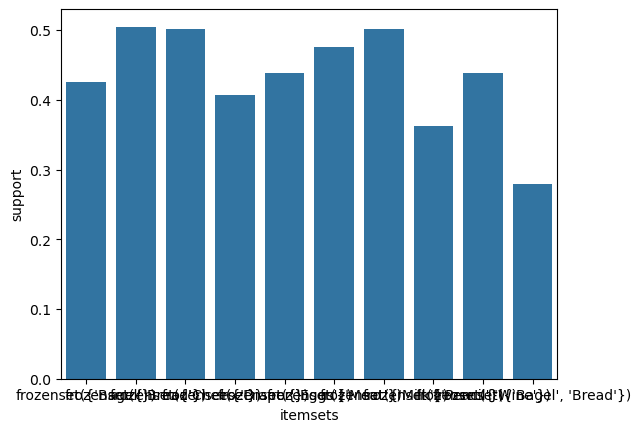

In [27]:
ax = sns.barplot(x='itemsets', y='support', data=freq_items[:10])

<Axes: xlabel='support', ylabel='Density'>

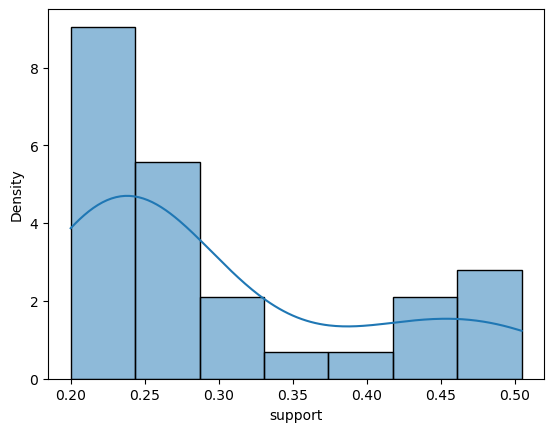

In [28]:
sns.histplot(freq_items['support'], kde=True, stat='density')

# Mining Association Rules

    association_rules(df, metric='confidence', min_threshold=0.8, support_only=False)

Metric can be set to confidence, lift, support, leverage and conviction.

The cell below keeps the rules with a confidence of at least 0.6. For a rule A → B, confidence = support(A ∪ B) / support(A), and lift = confidence / support(B); see the lecture slides on association rules and lift.

In [29]:
rules = association_rules(freq_items, metric="confidence", min_threshold=0.6)
rules.head()

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,frozenset({Bagel}),frozenset({Bread}),0.425397,0.504762,0.279365,0.656716,1.301042,1.0,0.064641,1.442650,0.402687,0.429268,0.306831,0.605088
1,frozenset({Eggs}),frozenset({Cheese}),0.438095,0.501587,0.298413,0.681159,1.358008,1.0,0.078670,1.563203,0.469167,0.465347,0.360288,0.638048
2,frozenset({Cheese}),frozenset({Meat}),0.501587,0.476190,0.323810,0.645570,1.355696,1.0,0.084958,1.477891,0.526414,0.495146,0.323360,0.662785
3,frozenset({Meat}),frozenset({Cheese}),0.476190,0.501587,0.323810,0.680000,1.355696,1.0,0.084958,1.557540,0.500891,0.495146,0.357962,0.662785
4,frozenset({Milk}),frozenset({Cheese}),0.501587,0.501587,0.304762,0.607595,1.211344,1.0,0.053172,1.270148,0.350053,0.436364,0.212690,0.607595


**What do you notice?** The rules *Meat → Cheese* and *Cheese → Meat* have the same support (0.32) and the same lift (1.36), but different confidence (0.68 and 0.65). Why?

<details>
<summary>Show the answer</summary>

Both rules describe the same baskets, those that contain Meat and Cheese, so their support is the same. Lift = support(A ∪ B) / (support(A) × support(B)) is symmetric in A and B. Confidence divides only by the support of the left-hand side: 0.324 / 0.476 (Meat) = 0.68, and 0.324 / 0.502 (Cheese) = 0.65.
</details>

# Result analysis: Visualizing results

## 1. Support vs Confidence

Each point is one rule: its support (how common the itemset is) against its confidence (how reliable the rule is).

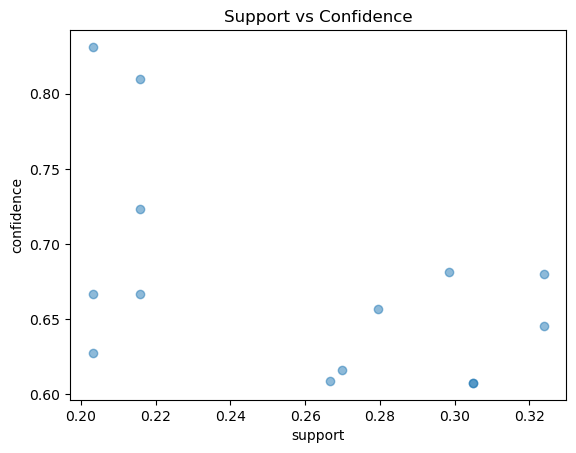

In [30]:
plt.scatter(rules['support'], rules['confidence'], alpha=0.5)
plt.xlabel('support')
plt.ylabel('confidence')
plt.title('Support vs Confidence')
plt.show()

## 2. Support vs Lift

The same rules, now with lift on the vertical axis.

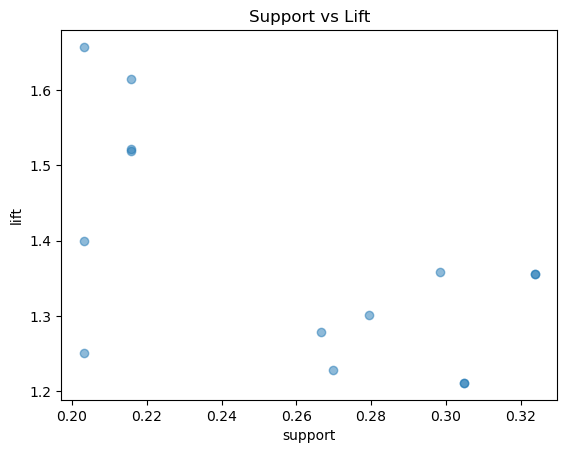

In [32]:
plt.scatter(rules['support'], rules['lift'], alpha=0.5)
plt.xlabel('support')
plt.ylabel('lift')
plt.title('Support vs Lift')
plt.show()

## 3. Lift vs Confidence

Lift against confidence, with a straight line fitted through the points (`np.polyfit` with degree 1) to show the trend.

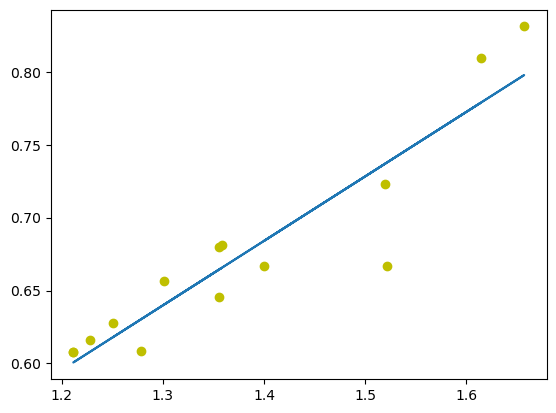

In [34]:
fit = np.polyfit(rules['lift'], rules['confidence'], 1)
fit_fn = np.poly1d(fit)
plt.plot(rules['lift'], rules['confidence'], 'yo', rules['lift'],fit_fn(rules['lift']))

# Correlation analysis

Correlation analysis continues in the notebook `02-Correlation Analysis.ipynb` in this week's `3 Tutorial` folder.